# Applied Data Science Capstone — SpaceX Falcon 9 Landing Prediction

**Student:** Pratham Dogra  
**Course:** Applied Data Science Capstone

## Project objective
Analyze historical Falcon 9 launches and build classification models to predict whether the first-stage landing outcome is successful.



## 1. Setup

In [1]:
%pip -q install pandas numpy matplotlib requests beautifulsoup4 lxml folium scikit-learn

from pathlib import Path
import os, json, sqlite3, time, warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path("/content")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures"
MAPS = ROOT / "outputs" / "maps"
for folder in [RAW, PROCESSED, FIGURES, MAPS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Setup completed.")
print("Working directory:", ROOT)

Setup completed.
Working directory: /content


## 2. SpaceX data collection (API-outage-safe)

The live API endpoint may be temporarily unavailable. We therefore retrieve the historical IBM/Coursera SpaceX capstone dataset from a static CSV mirror. This dataset includes the launch outcomes and engineered fields needed for the capstone analysis.

In [2]:
DATA_URLS = [
    "https://raw.githubusercontent.com/rampal-punia/IBM-DS-Capstone-Project-SpaceX/master/dataset_part_2.csv",
    "https://raw.githubusercontent.com/chuksoo/IBM-Data-Science-Capstone-SpaceX/main/dataset_part_2.csv",
    "https://raw.githubusercontent.com/Ahmed-Nezar/IBM-Data-Science-Capstone-SpaceX/main/dataset_part_2.csv",
]

def load_csv_from_sources(urls, destination, timeout=45):
    errors = []
    for url in urls:
        try:
            print("Trying dataset source:", url)
            response = requests.get(url, timeout=timeout)
            response.raise_for_status()
            if not response.content.strip():
                raise ValueError("Downloaded file is empty.")
            destination.write_bytes(response.content)
            frame = pd.read_csv(destination)
            if frame.empty:
                raise ValueError("CSV contains no rows.")
            print("Dataset loaded successfully:", len(frame), "rows")
            return frame, url
        except Exception as exc:
            errors.append(f"{url} -> {type(exc).__name__}: {exc}")
            print("Source unavailable; trying next mirror.")
    raise RuntimeError(
        "All public dataset mirrors failed. Upload the course file "
        "'dataset_part_2.csv' when Colab asks for it.\n" + "\n".join(errors)
    )

try:
    launches, DATA_SOURCE = load_csv_from_sources(
        DATA_URLS, RAW / "spacex_dataset_part_2.csv"
    )
except RuntimeError as download_error:
    print(download_error)
    print("\nPlease upload the IBM/Coursera file named dataset_part_2.csv.")
    try:
        from google.colab import files
        from io import BytesIO
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise ValueError("No CSV file was uploaded.")
        selected_name = "dataset_part_2.csv" if "dataset_part_2.csv" in csv_names else csv_names[0]
        launches = pd.read_csv(BytesIO(uploaded[selected_name]))
        launches.to_csv(RAW / "spacex_dataset_part_2.csv", index=False)
        DATA_SOURCE = f"Manual Colab upload: {selected_name}"
        print("Uploaded dataset loaded:", launches.shape)
    except Exception as upload_error:
        raise RuntimeError(
            "Dataset unavailable. Re-run this cell with internet enabled, "
            "or upload dataset_part_2.csv when prompted."
        ) from upload_error

print("Source used:", DATA_SOURCE)
print("Dataset shape:", launches.shape)
display(launches.head())

Trying dataset source: https://raw.githubusercontent.com/rampal-punia/IBM-DS-Capstone-Project-SpaceX/master/dataset_part_2.csv
Dataset loaded successfully: 90 rows
Source used: https://raw.githubusercontent.com/rampal-punia/IBM-DS-Capstone-Project-SpaceX/master/dataset_part_2.csv
Dataset shape: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## 3. Web-scraping data source

To keep this notebook reproducible when Wikipedia blocks automated requests or changes its tables, this section retrieves the archived web-scraped launch table from the same public capstone repository. It is a saved scrape, not a fresh scrape of Wikipedia.

In [3]:
SCRAPED_URLS = [
    "https://raw.githubusercontent.com/rampal-punia/IBM-DS-Capstone-Project-SpaceX/master/spacex_web_scraped.csv",
    "https://raw.githubusercontent.com/chuksoo/IBM-Data-Science-Capstone-SpaceX/main/spacex_web_scraped.csv",
]

web_launches = None
for url in SCRAPED_URLS:
    try:
        response = requests.get(url, timeout=45)
        response.raise_for_status()
        from io import BytesIO
        candidate = pd.read_csv(BytesIO(response.content))
        if not candidate.empty:
            web_launches = candidate
            candidate.to_csv(RAW / "spacex_web_scraped.csv", index=False)
            print("Archived web-scraped data loaded:", candidate.shape)
            print("Source:", url)
            display(candidate.head())
            break
    except Exception as exc:
        print("Archived scrape mirror unavailable:", type(exc).__name__)

if web_launches is None:
    print("No archived scrape mirror was available. Continuing with the main historical dataset.")

Archived web-scraped data loaded: (106, 11)
Source: https://raw.githubusercontent.com/rampal-punia/IBM-DS-Capstone-Project-SpaceX/master/spacex_web_scraped.csv


,Flight No.,Launch site,Payload,Payload mass,Orbit,Customer,Launch outcome,Version Booster,Booster landing,Date,Time
0,1,CCAFS,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success\n,F9 v1.0B0003.1,Failure,4 June 2010,18:45
1,2,CCAFS,Dragon,0,LEO,NASA,Success,F9 v1.0B0004.1,Failure,8 December 2010,15:43
2,3,CCAFS,Dragon,525 kg,LEO,NASA,Success,F9 v1.0B0005.1,No attempt\n,22 May 2012,07:44
3,4,CCAFS,SpaceX CRS-1,"4,700 kg",LEO,NASA,Success\n,F9 v1.0B0006.1,No attempt,8 October 2012,00:35
4,5,CCAFS,SpaceX CRS-2,"4,877 kg",LEO,NASA,Success\n,F9 v1.0B0007.1,No attempt\n,1 March 2013,15:10


## 4. Data wrangling

Normalize column names, verify required fields, convert numeric columns, and inspect missing values.

In [4]:
df = launches.copy()
df.columns = [str(c).strip() for c in df.columns]

# Normalize common names across published copies of the IBM capstone dataset.
rename_map = {
    "FlightNumber": "FlightNumber",
    "PayloadMass": "PayloadMass",
    "LaunchSite": "LaunchSite",
    "Outcome": "Outcome",
    "Class": "Class",
    "Date": "Date",
    "BoosterVersion": "BoosterVersion",
    "LandingPad": "LandingPad",
    "Serial": "Serial",
}
df = df.rename(columns=rename_map)

required = ["FlightNumber", "LaunchSite", "Class"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(
        f"The downloaded CSV is not the expected capstone dataset. "
        f"Missing columns: {missing_required}. Available columns: {list(df.columns)}"
    )

for col in ["FlightNumber", "PayloadMass", "Flights", "Block", "ReusedCount",
            "Longitude", "Latitude", "Class"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["Year"] = df["Date"].dt.year
elif "Year" not in df.columns:
    df["Year"] = np.nan

# Class is the IBM capstone target: 1 = successful landing, 0 = unsuccessful.
df = df.dropna(subset=["Class"]).copy()
df["Class"] = df["Class"].astype(int)
df = df[df["Class"].isin([0, 1])].copy()

print("Cleaned data shape:", df.shape)
print("Target counts (0 = failure, 1 = success):")
display(df["Class"].value_counts().sort_index().rename("count").to_frame())
print("Missing values:")
display(df.isna().sum().to_frame("missing_values"))
display(df.head())

Cleaned data shape: (90, 19)
Target counts (0 = failure, 1 = success):


,count
Class,
0,30
1,60


Missing values:


,missing_values
FlightNumber,0
Date,0
BoosterVersion,0
PayloadMass,0
Orbit,0
LaunchSite,0
Outcome,0
Flights,0
GridFins,0
Reused,0


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class,Year
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0,2010
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0,2012
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0,2013
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0,2013
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0,2013


## 5. Exploratory data analysis (EDA)

Explore landing outcomes, launch sites, payload mass, and launch year where available.

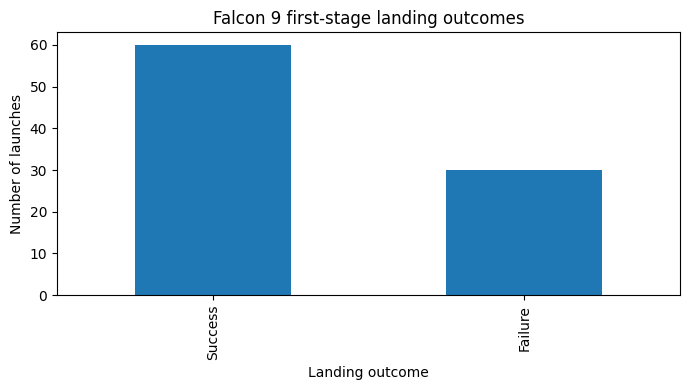

,launches,success_rate
LaunchSite,,
CCAFS SLC 40,55,0.600000
KSC LC 39A,22,0.772727
VAFB SLC 4E,13,0.769231


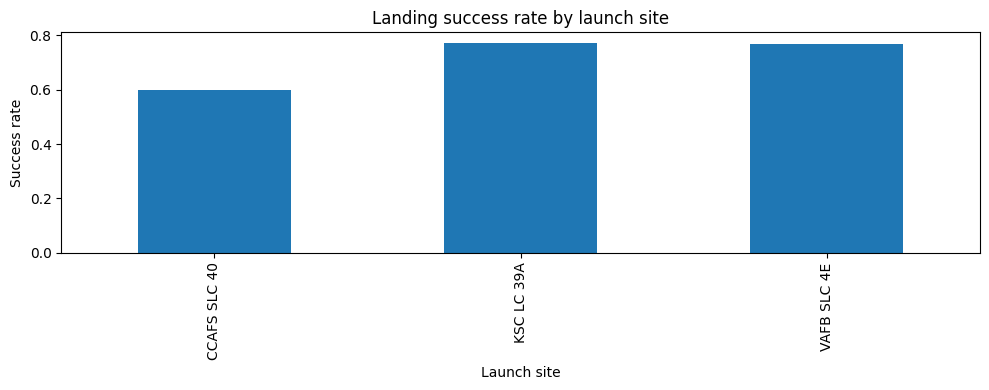

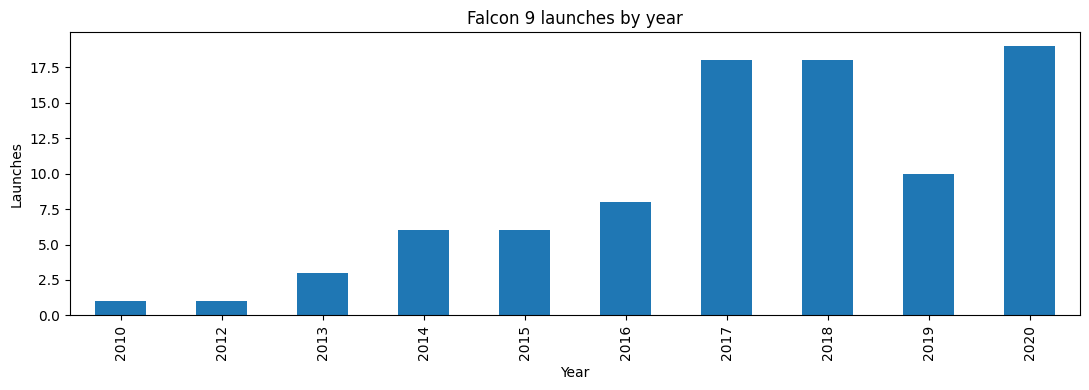

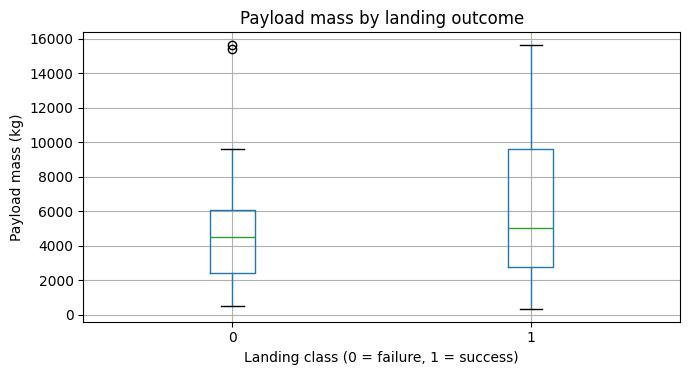

In [5]:
outcome_counts = df["Class"].map({0: "Failure", 1: "Success"}).value_counts()
ax = outcome_counts.plot(kind="bar", figsize=(7, 4), title="Falcon 9 first-stage landing outcomes")
ax.set_xlabel("Landing outcome")
ax.set_ylabel("Number of launches")
plt.tight_layout()
plt.savefig(FIGURES / "landing_outcomes.png", dpi=150)
plt.show()

if "LaunchSite" in df.columns:
    site_counts = df.groupby("LaunchSite")["Class"].agg(["count", "mean"]).sort_values("count", ascending=False)
    display(site_counts.rename(columns={"count": "launches", "mean": "success_rate"}))
    ax = site_counts["mean"].plot(kind="bar", figsize=(10, 4), title="Landing success rate by launch site")
    ax.set_xlabel("Launch site")
    ax.set_ylabel("Success rate")
    plt.tight_layout()
    plt.savefig(FIGURES / "success_by_launch_site.png", dpi=150)
    plt.show()

if "Year" in df.columns and df["Year"].notna().any():
    yearly = df.dropna(subset=["Year"]).groupby("Year")["Class"].agg(["count", "mean"])
    ax = yearly["count"].plot(kind="bar", figsize=(11, 4), title="Falcon 9 launches by year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Launches")
    plt.tight_layout()
    plt.savefig(FIGURES / "launches_by_year.png", dpi=150)
    plt.show()
else:
    print("Year field is unavailable; skipping year chart.")

if "PayloadMass" in df.columns and df["PayloadMass"].notna().any():
    df.boxplot(column="PayloadMass", by="Class", figsize=(7, 4))
    plt.title("Payload mass by landing outcome")
    plt.suptitle("")
    plt.xlabel("Landing class (0 = failure, 1 = success)")
    plt.ylabel("Payload mass (kg)")
    plt.tight_layout()
    plt.savefig(FIGURES / "payload_by_outcome.png", dpi=150)
    plt.show()

## 6. Exploratory data analysis with SQL

Load the cleaned dataset into an in-memory SQLite database and run summary queries.

In [6]:
sql_df = df.copy()
for col in sql_df.columns:
    if sql_df[col].dtype == "object":
        sql_df[col] = sql_df[col].astype(str)

with sqlite3.connect(":memory:") as con:
    sql_df.to_sql("spacex_launches", con, index=False, if_exists="replace")
    queries = {
        "Launches by site": '''
            SELECT LaunchSite, COUNT(*) AS total_launches,
                   ROUND(AVG(Class), 3) AS landing_success_rate
            FROM spacex_launches
            GROUP BY LaunchSite
            ORDER BY total_launches DESC
        ''',
        "Landing outcome counts": '''
            SELECT Class, COUNT(*) AS total
            FROM spacex_launches
            GROUP BY Class
            ORDER BY Class
        '''
    }
    if "Year" in sql_df.columns:
        queries["Launches by year"] = '''
            SELECT Year, COUNT(*) AS total_launches,
                   ROUND(AVG(Class), 3) AS landing_success_rate
            FROM spacex_launches
            WHERE Year IS NOT NULL
            GROUP BY Year
            ORDER BY Year
        '''
    for title, query in queries.items():
        print("\n" + title)
        display(pd.read_sql_query(query, con))


Launches by site


,LaunchSite,total_launches,landing_success_rate
0,CCAFS SLC 40,55,0.600
1,KSC LC 39A,22,0.773
2,VAFB SLC 4E,13,0.769



Landing outcome counts


,Class,total
0,0,30
1,1,60



Launches by year


,Year,total_launches,landing_success_rate
0,2010,1,0.000
1,2012,1,0.000
2,2013,3,0.000
3,2014,6,0.333
4,2015,6,0.333
5,2016,8,0.625
6,2017,18,0.833
7,2018,18,0.611
8,2019,10,0.900
9,2020,19,0.842


## 7. Folium launch-site map

Use longitude and latitude stored in the historical dataset. If the coordinates are absent, show a clear message rather than making another API request.

In [7]:
import folium

map_df = df.dropna(subset=["Longitude", "Latitude"]).copy() if {"Longitude", "Latitude"}.issubset(df.columns) else pd.DataFrame()

if not map_df.empty:
    center = [float(map_df["Latitude"].mean()), float(map_df["Longitude"].mean())]
    launch_map = folium.Map(location=center, zoom_start=4)
    for _, row in map_df.drop_duplicates(subset=["LaunchSite"]).iterrows():
        site = row.get("LaunchSite", "Launch site")
        folium.Marker(
            [float(row["Latitude"]), float(row["Longitude"])],
            popup=str(site),
            tooltip=str(site)
        ).add_to(launch_map)
    map_file = MAPS / "launch_sites.html"
    launch_map.save(str(map_file))
    print("Interactive map saved:", map_file)
    display(launch_map)
else:
    print("No valid launch-site coordinates in this CSV. Map generation skipped.")

Interactive map saved: /content/outputs/maps/launch_sites.html


## 8. Feature engineering

Select features present in the historical dataset. The target is `Class` (1 = successful landing, 0 = unsuccessful landing).

In [8]:
candidate_numeric = ["FlightNumber", "PayloadMass", "Flights", "GridFins", "Reused",
                     "Legs", "Block", "ReusedCount", "Year", "Longitude", "Latitude"]
candidate_categorical = ["Orbit", "LaunchSite", "LandingPad", "Serial", "BoosterVersion"]

numeric_features = [c for c in candidate_numeric if c in df.columns and df[c].notna().any()]
categorical_features = [c for c in candidate_categorical if c in df.columns and df[c].notna().any()]
feature_columns = numeric_features + categorical_features

if not feature_columns:
    raise ValueError("No usable predictor columns were found in the downloaded dataset.")

model_df = df[feature_columns + ["Class"]].copy()
model_df = model_df.dropna(subset=["Class"])
X = model_df[feature_columns].copy()
y = model_df["Class"].astype(int).copy()

print("Predictor columns:", feature_columns)
print("Rows available for modelling:", len(model_df))
print("Target distribution:")
display(y.value_counts().sort_index().rename(index={0: "Failure", 1: "Success"}).to_frame("count"))

Predictor columns: ['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Year', 'Longitude', 'Latitude', 'Orbit', 'LaunchSite', 'LandingPad', 'Serial', 'BoosterVersion']
Rows available for modelling: 90
Target distribution:


,count
Class,
Failure,30
Success,60


## 9. Classification models

Train Logistic Regression, Support Vector Machine, Decision Tree, and K-Nearest Neighbors. Preprocessing is fitted only on the training data through scikit-learn pipelines.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

class_counts = y.value_counts()
if len(class_counts) < 2 or class_counts.min() < 2 or len(y) < 12:
    raise ValueError(
        "Not enough examples in both target classes for a stratified train/test split. "
        f"Class counts: {class_counts.to_dict()}"
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

numeric_cols = [c for c in numeric_features if c in X_train.columns]
categorical_cols = [c for c in categorical_features if c in X_train.columns]

transformers = []
if numeric_cols:
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    transformers.append(("numeric", numeric_pipe, numeric_cols))
if categorical_cols:
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(("categorical", categorical_pipe, categorical_cols))

preprocessor = ColumnTransformer(transformers=transformers)

knn_neighbors = max(1, min(5, len(X_train)))
model_definitions = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "SVM": SVC(class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42, class_weight="balanced"),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=knn_neighbors)
}

trained_models = {}
score_rows = []
for model_name, estimator in model_definitions.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[model_name] = pipeline
    score_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

scores = pd.DataFrame(score_rows).sort_values(
    ["F1-score", "Accuracy"], ascending=False
).reset_index(drop=True)
display(scores)
scores.to_csv(ROOT / "outputs" / "model_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1-score
0,SVM,0.826087,0.789474,1.000000,0.882353
1,K-Nearest Neighbors,0.826087,0.789474,1.000000,0.882353
2,Logistic Regression,0.782609,0.777778,0.933333,0.848485
3,Decision Tree,0.739130,0.800000,0.800000,0.800000


## 10. Model evaluation

Compare model metrics and inspect the confusion matrix for the highest-F1 model.

Selected model (highest test F1-score): SVM
                 precision    recall  f1-score   support

Landing failure       1.00      0.50      0.67         8
Landing success       0.79      1.00      0.88        15

       accuracy                           0.83        23
      macro avg       0.89      0.75      0.77        23
   weighted avg       0.86      0.83      0.81        23



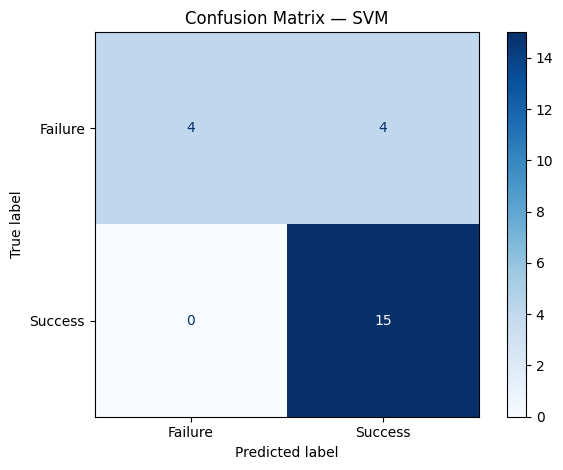

In [10]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_model_name = scores.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Selected model (highest test F1-score):", best_model_name)
print(classification_report(
    y_test, best_predictions,
    labels=[0, 1],
    target_names=["Landing failure", "Landing success"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    labels=[0, 1],
    display_labels=["Failure", "Success"],
    cmap="Blues"
)
plt.title("Confusion Matrix — " + best_model_name)
plt.tight_layout()
plt.savefig(FIGURES / "confusion_matrix.png", dpi=150)
plt.show()

## 11. Dashboard data and project outputs

Export a clean modelling dataset, metrics, and a JSON summary.

In [11]:
dashboard_data = model_df.copy()
dashboard_path = PROCESSED / "spacex_dashboard_data.csv"
dashboard_data.to_csv(dashboard_path, index=False)

summary = {
    "data_source": DATA_SOURCE,
    "rows_in_dataset": int(len(df)),
    "rows_used_for_model": int(len(model_df)),
    "features": feature_columns,
    "best_model_by_f1": best_model_name,
    "metrics": scores.to_dict(orient="records")
}
summary_path = ROOT / "outputs" / "project_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Dashboard dataset:", dashboard_path)
print("Model comparison:", ROOT / "outputs" / "model_comparison.csv")
print("Project summary:", summary_path)
print("\nGenerated output files:")
for path in sorted((ROOT / "outputs").rglob("*")):
    if path.is_file():
        print(path)

Dashboard dataset: /content/data/processed/spacex_dashboard_data.csv
Model comparison: /content/outputs/model_comparison.csv
Project summary: /content/outputs/project_summary.json

Generated output files:
/content/outputs/figures/confusion_matrix.png
/content/outputs/figures/landing_outcomes.png
/content/outputs/figures/launches_by_year.png
/content/outputs/figures/payload_by_outcome.png
/content/outputs/figures/success_by_launch_site.png
/content/outputs/maps/launch_sites.html
/content/outputs/model_comparison.csv
/content/outputs/project_summary.json


## 12. Conclusion

This section summarizes the actual results calculated in the current run. Interpret these results as a teaching-project evaluation, not as a guarantee of future launch outcomes.

In [12]:
landing_success_rate = float(df["Class"].mean())
best_row = scores.iloc[0]

print("SPACEX FALCON 9 LANDING PREDICTION — SUMMARY")
print("=" * 52)
print(f"Historical launch records analysed: {len(df)}")
print(f"Landing success rate in this dataset: {landing_success_rate:.1%}")
print(f"Number of predictors: {len(feature_columns)}")
print(f"Best model by F1-score: {best_model_name}")
print(f"Accuracy:  {best_row['Accuracy']:.3f}")
print(f"Precision: {best_row['Precision']:.3f}")
print(f"Recall:    {best_row['Recall']:.3f}")
print(f"F1-score:  {best_row['F1-score']:.3f}")

print("\nLIMITATIONS")
print("- The notebook uses a historical published dataset, not live SpaceX telemetry.")
print("- Results depend on the dataset snapshot and random train/test split.")
print("- The feature set does not include every engineering or weather variable.")
print("- A chronological split and additional validation are recommended for future-launch forecasting.")
print("\nNotebook workflow completed.")

SPACEX FALCON 9 LANDING PREDICTION — SUMMARY
Historical launch records analysed: 90
Landing success rate in this dataset: 66.7%
Number of predictors: 16
Best model by F1-score: SVM
Accuracy:  0.826
Precision: 0.789
Recall:    1.000
F1-score:  0.882

LIMITATIONS
- The notebook uses a historical published dataset, not live SpaceX telemetry.
- Results depend on the dataset snapshot and random train/test split.
- The feature set does not include every engineering or weather variable.
- A chronological split and additional validation are recommended for future-launch forecasting.

Notebook workflow completed.
